1. Scenario: the scenario you found, why it fits the situations above, and the questions you want to answer (2 to 3 sentences) 

At Hospital Cempaka, the raw blood test data coming from the lab equipment is really messy, filled with missing rows and weird scientific codes like 5.40E-79. This project fits a data engineering pipeline perfectly because medical data can't be used as is it needs to be cleaned and formatted automatically before it's safe for doctors to use. By setting up this pipeline, we can instantly flag critical blood results like severe anemia or crazy high white blood cell counts so doctors can step in right away.

2. Data source : where the data came from, with the URL and how you obtained it 

In [ ]:
## 2. Data source

- **Dataset:** NHANES August 2021–August 2023, *Complete Blood Count with 5-Part Differential in Whole Blood* (file `CBC_L`)
- **Publisher:** National Center for Health Statistics (NCHS), US Centers for Disease Control and Prevention (CDC). First published September 2024.
- **Documentation page:** https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/CBC_L.htm
- **Data file:** https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/CBC_L.xpt (SAS transport format)
- **How we obtained it:** We downloaded the open public-use file directly from the CDC website (no scraping) and read it with `pandas.read_sas`. Reading the original `.xpt` file keeps SAS missing values as proper `NaN`.
- **Size:** 8,727 participants (rows) and 23 columns: the ID `SEQN`, the survey weight `WTPH2YR`, and 21 blood-test results.
- **How it maps to the capstone:** Hospital Cempaka's pathology lab analyser produces a CBC results file (step 2 of our pipeline). The CDC measured these values with a Beckman Coulter DxH 800 analyser, so this dataset acts as a stand-in for that file.
- **Terms of use:** The files are public and free to download. NCHS data come with a condition that they are used only for statistical analysis and never to identify individuals, and we follow that.

In [11]:
import io, requests
import pandas as pd

DATA_URL = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/CBC_L.xpt"
try:
    r = requests.get(DATA_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    r.raise_for_status()
    df_raw = pd.read_sas(io.BytesIO(r.content), format="xport")
    print("Loaded from CDC URL")
except Exception as e:
    print("Download failed, using local file:", e)
    df_raw = pd.read_sas("CBC_L.xpt", format="xport")   # download the file manually and put it beside the notebook

df = df_raw.copy()   # df_raw is never edited, so everyone can compare before/after
print(df.shape)
df.head()

Loaded from CDC URL
(8727, 23)


,SEQN,WTPH2YR,LBXWBCSI,LBXLYPCT,LBXMOPCT,LBXNEPCT,LBXEOPCT,LBXBAPCT,LBDLYMNO,LBDMONO,...,LBXRBCSI,LBXHGB,LBXHCT,LBXMCVSI,LBXMC,LBXMCHSI,LBXRDW,LBXPLTSI,LBXMPSI,LBXNRBC
0,130378.0,5.604213e+04,4.7,40.8,6.8,46.1,5.2,1.2,1.9,0.3,...,5.19,15.7,45.3,87.4,34.6,30.2,12.9,259.0,7.8,0.3
1,130379.0,3.743571e+04,6.3,25.4,14.2,57.3,2.5,0.7,1.6,0.9,...,4.59,15.2,43.9,95.8,34.5,33.0,12.8,221.0,8.5,0.1
2,130380.0,8.532884e+04,5.7,29.9,5.5,58.5,5.3,0.9,1.7,0.3,...,4.86,13.8,40.1,82.5,34.4,28.3,13.3,235.0,9.1,0.1
3,130381.0,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,5.963893e+04,11.4,29.9,8.3,60.1,1.2,0.6,3.4,0.9,...,4.61,12.3,36.5,79.2,33.6,26.7,14.6,342.0,7.4,0.1


3.

4.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the raw CBC dataset
cbc_df = pd.read_csv("../CBC_L.csv")
print("Dataset shape (rows, columns):", cbc_df.shape)
cbc_df.head()

Dataset shape (rows, columns): (8727, 24)


,Unnamed: 0,SEQN,WTPH2YR,LBXWBCSI,LBXLYPCT,LBXMOPCT,LBXNEPCT,LBXEOPCT,LBXBAPCT,LBDLYMNO,...,LBXRBCSI,LBXHGB,LBXHCT,LBXMCVSI,LBXMC,LBXMCHSI,LBXRDW,LBXPLTSI,LBXMPSI,LBXNRBC
0,0,130378.0,5.604213e+04,4.7,40.8,6.8,46.1,5.2,1.2,1.9,...,5.19,15.7,45.3,87.4,34.6,30.2,12.9,259.0,7.8,0.3
1,1,130379.0,3.743571e+04,6.3,25.4,14.2,57.3,2.5,0.7,1.6,...,4.59,15.2,43.9,95.8,34.5,33.0,12.8,221.0,8.5,0.1
2,2,130380.0,8.532884e+04,5.7,29.9,5.5,58.5,5.3,0.9,1.7,...,4.86,13.8,40.1,82.5,34.4,28.3,13.3,235.0,9.1,0.1
3,3,130381.0,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,130382.0,5.963893e+04,11.4,29.9,8.3,60.1,1.2,0.6,3.4,...,4.61,12.3,36.5,79.2,33.6,26.7,14.6,342.0,7.4,0.1


In [5]:
def profile_cbc(df):
    return pd.DataFrame({
        "data_type": df.dtypes,
        "non_null_count": df.count(),
        "null_count": df.isna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "unique_count": df.nunique(),
        "example_value": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None)
    })

# Run profiling on the CBC table
profile_cbc(cbc_df)

,data_type,non_null_count,null_count,null_pct,unique_count,example_value
Unnamed: 0,int64,8727,0,0.00,8727,0.00000
SEQN,float64,8727,0,0.00,8727,130378.00000
WTPH2YR,float64,8727,0,0.00,7425,56042.12941
LBXWBCSI,float64,7593,1134,12.99,145,4.70000
LBXLYPCT,float64,7582,1145,13.12,557,40.80000
LBXMOPCT,float64,7582,1145,13.12,160,6.80000
LBXNEPCT,float64,7582,1145,13.12,597,46.10000
LBXEOPCT,float64,7582,1145,13.12,159,5.20000
LBXBAPCT,float64,7582,1145,13.12,35,1.20000
LBDLYMNO,float64,7582,1145,13.12,76,1.90000


In [ ]:
lab_cols = [c for c in cbc_df.columns if c not in ["Unnamed: 0", "SEQN", "WTPH2YR"]]
no_lab_rows = cbc_df[lab_cols].isna().all(axis=1)   # baris tiada langsung keputusan darah
code_mask = cbc_df["WTPH2YR"] < 1e-10                # kod 5.4E-79 (hanya WTPH2YR)

quality_checks = {
    # 1. Completeness
    "Completeness: Missing Hemoglobin (LBXHGB)": cbc_df["LBXHGB"].isna().sum(),
    "Completeness: Missing WBC (LBXWBCSI)": cbc_df["LBXWBCSI"].isna().sum(),
    "Completeness: Missing Platelet (LBXPLTSI)": cbc_df["LBXPLTSI"].isna().sum(),
    "Completeness: Missing Hematocrit (LBXHCT)": cbc_df["LBXHCT"].isna().sum(),
    "Completeness: Rows with NO lab results at all": no_lab_rows.sum(),

    # 2. Validity
    "Validity: Detection-limit code 5.4E-79 in WTPH2YR": code_mask.sum(),
    "Validity: Code rows that also have no lab results": (code_mask & no_lab_rows).sum(),
    "Validity: SEQN stored as float": cbc_df["SEQN"].dtype == "float64",

    # 3. Redundancy
    "Redundancy: Unnecessary index column (Unnamed: 0)": "Unnamed: 0" in cbc_df.columns,

    # 4. Outliers
    "Outliers: High WBC / Leukocytosis (> 11.0)": (cbc_df["LBXWBCSI"] > 11.0).sum(),
    "Outliers: Low WBC / Leukopenia (< 4.0)": (cbc_df["LBXWBCSI"] < 4.0).sum(),
    "Outliers: Low HGB / Anemia (< 10.0)": (cbc_df["LBXHGB"] < 10.0).sum(),
}
pd.Series(quality_checks).to_frame(name="issue_count")

,issue_count
Completeness: Missing Hemoglobin (LBXHGB),1134
Completeness: Missing WBC (LBXWBCSI),1134
Completeness: Missing Platelet (LBXPLTSI),1134
Completeness: Missing Hematocrit (LBXHCT),1134
Completeness: Rows with NO lab results at all,1134
Validity: Detection-limit code 5.4E-79 in WTPH2YR,1101
Validity: Code rows that also have no lab results,1101
Validity: SEQN stored as float,True
Redundancy: Unnecessary index column (Unnamed: 0),True
Outliers: High WBC / Leukocytosis (> 11.0),299


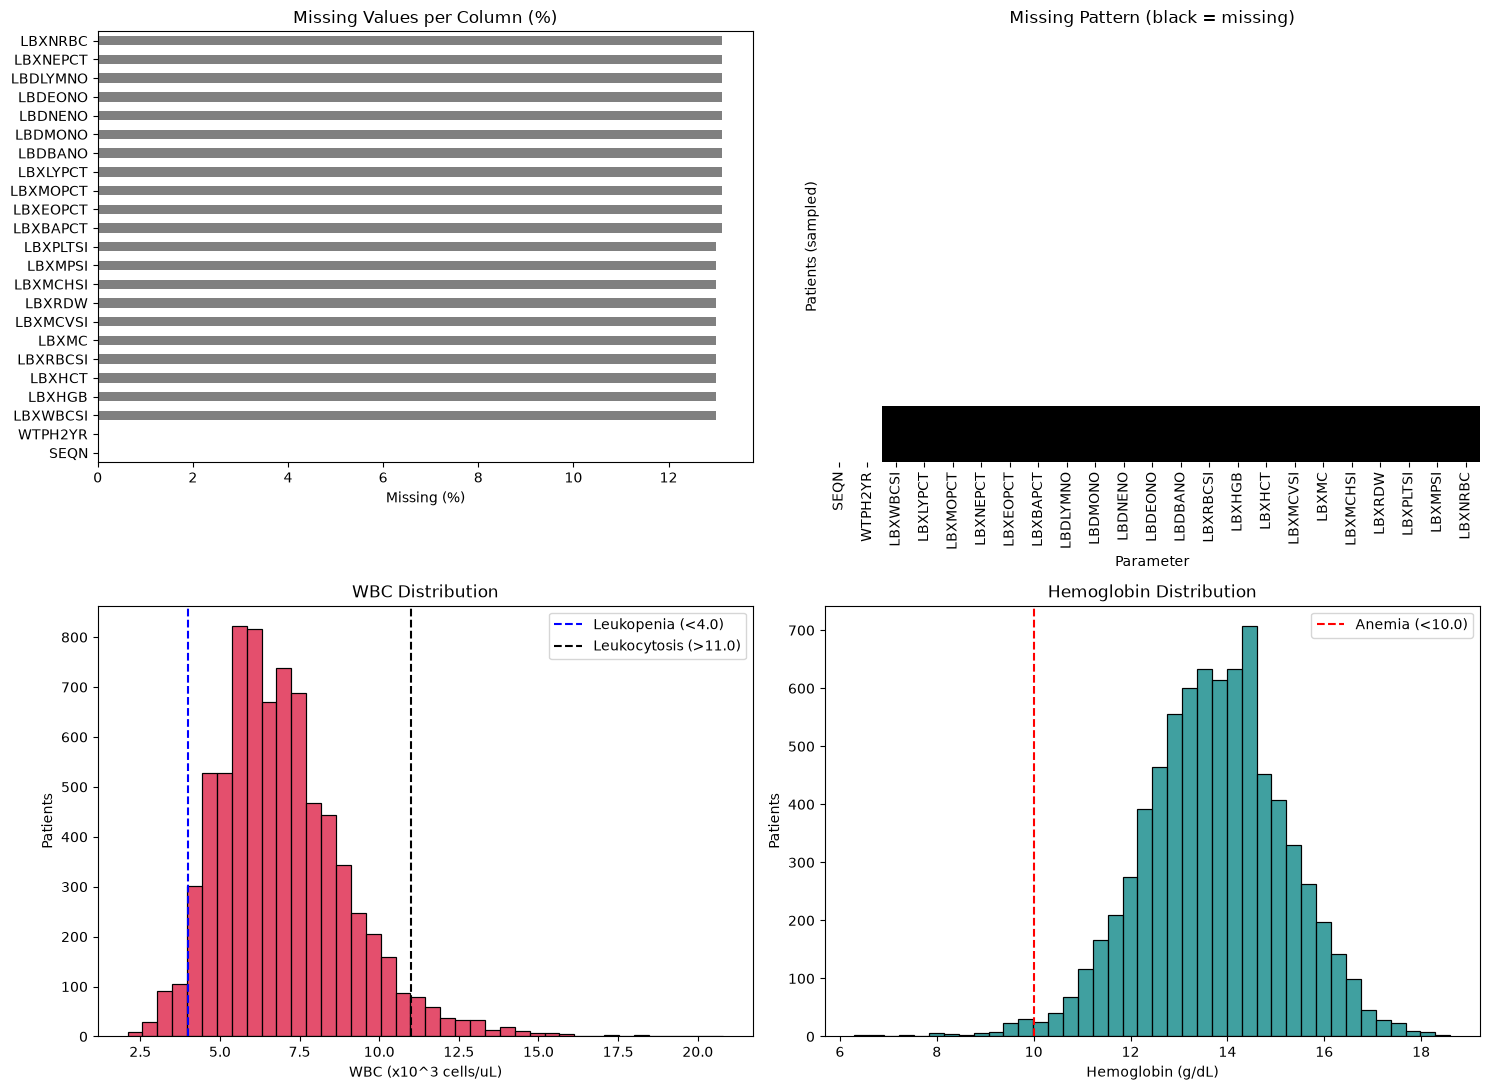

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Chart 1: % missing values per column
miss_pct = (cbc_df.drop(columns=["Unnamed: 0"]).isna().mean() * 100).sort_values()
miss_pct.plot(kind="barh", ax=axes[0, 0], color="gray")
axes[0, 0].set_title("Missing Values per Column (%)")
axes[0, 0].set_xlabel("Missing (%)")

# Chart 2: Heatmap missing pattern
sample = cbc_df.drop(columns=["Unnamed: 0"]).sort_values("LBXHGB", na_position="last").iloc[::20]
sns.heatmap(sample.isna(), cbar=False, yticklabels=False, cmap="Greys", ax=axes[0, 1])
axes[0, 1].set_title("Missing Pattern (black = missing)")
axes[0, 1].set_xlabel("Parameter")
axes[0, 1].set_ylabel("Patients (sampled)")

# Chart 3: Histogram WBC + threshold clinical
sns.histplot(cbc_df["LBXWBCSI"].dropna(), bins=40, ax=axes[1, 0], color="crimson")
axes[1, 0].axvline(4.0, color="blue", ls="--", label="Leukopenia (<4.0)")
axes[1, 0].axvline(11.0, color="black", ls="--", label="Leukocytosis (>11.0)")
axes[1, 0].set_title("WBC Distribution")
axes[1, 0].set_xlabel("WBC (x10^3 cells/uL)")
axes[1, 0].set_ylabel("Patients")
axes[1, 0].legend()

# Chart 4: Histogram Hemoglobin + threshold anemia
sns.histplot(cbc_df["LBXHGB"].dropna(), bins=40, ax=axes[1, 1], color="teal")
axes[1, 1].axvline(10.0, color="red", ls="--", label="Anemia (<10.0)")
axes[1, 1].set_title("Hemoglobin Distribution")
axes[1, 1].set_xlabel("Hemoglobin (g/dL)")
axes[1, 1].set_ylabel("Patients")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

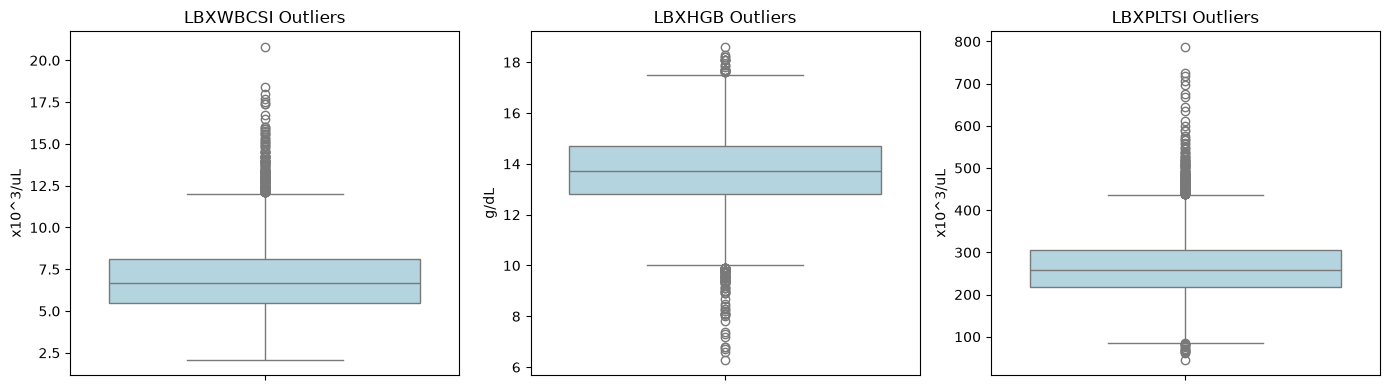

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, unit in zip(axes, ["LBXWBCSI", "LBXHGB", "LBXPLTSI"],
                         ["x10^3/uL", "g/dL", "x10^3/uL"]):
    sns.boxplot(y=cbc_df[col].dropna(), ax=ax, color="lightblue")
    ax.set_title(f"{col} Outliers")
    ax.set_ylabel(unit)
plt.tight_layout()
plt.show()

5.

In [9]:
import os, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

assert "cbc_df" in globals(), "cbc_df not found: run the cell that loads CBC_L.csv first"
print("cbc_df shape:", cbc_df.shape)

cbc_df shape: (8727, 24)


## PII and Bias Risk
This part evaluates which fields could identify an individual (PII), what sampling bias and group imbalance risks that exist in Hospital Cempaka’s pipeline ML

In [10]:
cbc_pii = cbc_df.drop(columns=["Unnamed: 0"], errors="ignore").copy()
cbc_pii = cbc_pii.dropna(subset=["SEQN"])
cbc_pii["SEQN"] = cbc_pii["SEQN"].astype("int64")

SALT = "datahood-demo-salt"   # in a real system, store the salt securely, not in code
cbc_pii["patient_hash"] = cbc_pii["SEQN"].astype(str).map(
    lambda x: hashlib.sha256((SALT + x).encode()).hexdigest()[:16]
)

cbc_ml = cbc_pii.drop(columns=["SEQN"])   # ML version: original ID removed
cbc_ml[["patient_hash", "LBXHGB", "LBXWBCSI"]].head()

,patient_hash,LBXHGB,LBXWBCSI
0,6b47fe2a03cfee22,15.7,4.7
1,ba659c60ba0e1513,15.2,6.3
2,02d276b3125d2bd1,13.8,5.7
3,39dec7d207f0132d,NaN,NaN
4,f0fbb082b34e3cb1,12.3,11.4


### PII findings

| Field | Type | Risk | Reason |
|---|---|---|---|
| `SEQN` | Respondent identifier | Medium | A unique ID that can be linked across NHANES files; in a real hospital it would map to a specific patient |
| `LBX*` / `LBD*` | Health data | Medium | Blood test results are sensitive personal data under Malaysia's PDPA 2010 |
| `WTPH2YR` | Survey weight | Low | Not identifying by itself, but it is tied to the sampling design |
| Age, gender, ethnicity (from `DEMO_L`) | Quasi-identifiers | Medium-high | Combining several attributes can narrow a group down until an individual can be re-identified |

**Handling:** In the Silver layer, `SEQN` is pseudonymized with a salted SHA-256 hash (`patient_hash`) and the original column is dropped from the ML dataset (`cbc_ml`), so diagnostic values cannot be traced back to a patient without the salt. Demographic fields are used only for bias checks and are not model features. In production, data would also be encrypted at rest and in transit, with access logged.

6.